# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024160066          # <-- your full roll number
NAME = "PRERNA GARG"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [5]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024160066   Name: PRERNA GARG   Fingerprint: BE10EE2A   Tickets: 13

Ticket_ID                                                                                         Ticket_Text
      T01                            WiFi crashes while opening during the lab. It works on another computer.
      T02                                                                Email me at helpdesk@university.edu.
      T03         I tried restarting the student portal when I use mobile hotspot. I don't know what changed.
      T04                                    VPN keeps asking for login since yesterday. It worked yesterday.
      T05                                                                         The file is 95.5% uploaded.
      T06                             I tried restarting the password when I use mobile hotspot. Please help.
      T07                                           The wifi keeps disconnecting. I have tried several times!
      T08                            

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [6]:

# Q1: Preprocessing pipeline

results = []

for i, row in df.iterrows():
    output = process_ticket(row["Ticket_Text"])

    results.append({
        "Ticket_ID": row["Ticket_ID"],
        "Number of Sentences": len(output["sentences"]),
        "Number of Tokens": len(output["tokens"]),
        "Number of Punctuation Tokens": len(output["punct"]),
        "Number of Stopwords": len(output["stops"]),
        "Number of Unique Tokens": len(set(output["tokens"])),
        "Number of Final Tokens": len(output["final"])
    })

result_df = pd.DataFrame(results)
total_row = {"Ticket_ID": "TOTAL"}
for col in result_df.columns[1:]:
    if col == "Number of Unique Tokens":
        total_row[col] = len(set(
            token
            for tokens in df["Ticket_Text"].apply(
                lambda text: process_ticket(text)["tokens"]
            )
            for token in tokens
        ))
    else:
        total_row[col] = result_df[col].sum()

result_df.loc[len(result_df)] = total_row
print(result_df.to_string(index=False))
selected_ticket = df.iloc[12]
output = process_ticket(selected_ticket["Ticket_Text"])
print("\nSelected Ticket:", selected_ticket["Ticket_ID"])
print("Ticket Text:", selected_ticket["Ticket_Text"])
print("Actual Tokens:", output["tokens"])
print("Punctuation Tokens:", output["punct"])
print("Stopwords:", output["stops"])
print("Final Tokens:", output["final"])


Ticket_ID  Number of Sentences  Number of Tokens  Number of Punctuation Tokens  Number of Stopwords  Number of Unique Tokens  Number of Final Tokens
      T01                    2                14                             2                    5                       13                       7
      T02                    1                 7                             2                    2                        7                       3
      T03                    2                19                             2                    7                       16                      10
      T04                    2                12                             2                    2                       10                       8
      T05                    1                 7                             2                    2                        7                       3
      T06                    2                14                             2                    4       

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* 'n't', It came from contractions split into separate word tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [10]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

# Your code
import re
for i, row in df.iterrows():
  text=row["Ticket_Text"]
  print("\nTicket D:", row["Ticket_ID"])
  print("Words longer than 5 letters:",re.findall(r"\b[A-Za-z]{6,}\b",text))
  print("Numbers and versions:",re.findall(r"\b\d+(?:\.\d+)+|\b\d[\d,]*\b", text))
  print("Capitalized words:",re.findall(r"\b[A-Z][a-zA-Z]*\b", text))
  print("Words beginning with a vowel:",re.findall(r"\b[aeiouAEIOU][a-zA-Z]*\b", text))
def replace_patterns(text):
        text = re.sub(
        r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b",
        "<EMAIL>",
        text
        )
        text = re.sub(
        r"\b(?:https?://|www\.)[^\s<>.,;!?]+(?:\.[^\s<>.,;!?]+)*",
        "<URL>",
        text,
        flags=re.IGNORECASE
        )
        text = re.sub(
        r"(?<!\w)(?:\+91[-.\s]?)?(?:\d{5}[-.\s]?\d{5}|\d{4}[-.\s]?\d{3}[-.\s]?\d{4})(?!\w)",
        "<PHONE>",
        text
        )
        return text
for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Replaced:", replace_patterns(line))



Ticket D: T01
Words longer than 5 letters: ['crashes', 'opening', 'during', 'another', 'computer']
Numbers and versions: []
Capitalized words: ['WiFi', 'It']
Words beginning with a vowel: ['opening', 'It', 'on', 'another']

Ticket D: T02
Words longer than 5 letters: ['helpdesk', 'university']
Numbers and versions: []
Capitalized words: ['Email']
Words beginning with a vowel: ['Email', 'at', 'university', 'edu']

Ticket D: T03
Words longer than 5 letters: ['restarting', 'student', 'portal', 'mobile', 'hotspot', 'changed']
Numbers and versions: []
Capitalized words: ['I', 'I', 'I']
Words beginning with a vowel: ['I', 'I', 'use', 'I']

Ticket D: T04
Words longer than 5 letters: ['asking', 'yesterday', 'worked', 'yesterday']
Numbers and versions: []
Capitalized words: ['VPN', 'It']
Words beginning with a vowel: ['asking', 'It']

Ticket D: T05
Words longer than 5 letters: ['uploaded']
Numbers and versions: ['95.5']
Capitalized words: ['The']
Words beginning with a vowel: ['is', 'uploaded']

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* 11 words, these are It (3 times), The (3 times), Please (2 times), Email (1 time), Nothing (1 time), and Is (1 time). The other capitalized words are proper names, acronyms, or the letter "I".

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [11]:
# Your code
from nltk.tokenize import RegexpTokenizer,word_tokenize
pattern=(
    r"https?://[^\s<>]+|"
    r"www\.[^\s<>]+|"
    r"[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}|"
    r"\+?\d[\d().\-\s]{7,}\d|"
    r"\d+(?:\.\d+)+|"
    r"[A-Za-z]+(?:[-'][A-Za-z]+)+|"
    r"[A-Za-z]+|"
    r"\d+|"
    r"[^\w\s]"
)
tokenizer=RegexpTokenizer(pattern)
def my_tokenize(text):
  return tokenizer.tokenize(text)
for line in TEST_LINES:
  print("\nText:",line)
  print("Custom Tokens:",my_tokenize(line))
  print("word_tokenize:",word_tokenize(line))
for i, row in df.iterrows():
    text = row["Ticket_Text"]

    print("\nTicket ID:", row["Ticket_ID"])
    print("Custom Tokens:", my_tokenize(text))
    print("word_tokenize:", word_tokenize(text))





Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom Tokens: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it.']
word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom Tokens: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
word_tokenize: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Cu

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 3 tickets (T02, T03, and T09). my_tokenize keeps the email address in T02 as one piece and keeps contractions like "don't" and "couldn't" in T03 and T09 as single words.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [13]:
# Your code
from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag
import pandas as pd
porter = PorterStemmer()
lancaster = LancasterStemmer()
lemmatizer = WordNetLemmatizer()
unique_tokens = sorted(set(
    token.lower()
    for row in df["Ticket_Text"]
    for token in process_ticket(row)["final"]
))
suffixes = ["ing", "ed", "es", "s", "ly", "er"]
suffix = next(
    (s for s in suffixes
     if sum(word.endswith(s) for word in unique_tokens) >= 2),
    "ing"
)
regex_stemmer = RegexpStemmer(regexp=suffix + r"$")
print("Selected suffix:", suffix)
print("Words supporting suffix:", [
    word for word in unique_tokens if word.endswith(suffix)
])
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return "a"
    elif tag.startswith("V"):
        return "v"
    elif tag.startswith("N"):
        return "n"
    elif tag.startswith("R"):
        return "r"
    return "n"
tagged_words = pos_tag(unique_tokens)
results = []
for word, tag in tagged_words:
    porter_result = porter.stem(word)
    lancaster_result = lancaster.stem(word)
    regex_result = regex_stemmer.stem(word)
    pos = get_wordnet_pos(tag)
    lemma_result = lemmatizer.lemmatize(word, pos=pos)
    if len(set([
        porter_result,
        lancaster_result,
        regex_result,
        lemma_result
    ])) > 1:
        results.append({
            "Word": word,
            "Porter Stem": porter_result,
            "Lancaster Stem": lancaster_result,
            "Regexp Stem": regex_result,
            "POS Lemma": lemma_result,
            "POS Tag": tag
        })
comparison_df = pd.DataFrame(results)
print("\nWords with differing outputs:")
print(comparison_df.to_string(index=False))

Selected suffix: ing
Words supporting suffix: ['asking', 'disconnecting', 'nothing', 'opening', 'responding', 'restarting', 'showing']

Words with differing outputs:
     Word Porter Stem Lancaster Stem Regexp Stem POS Lemma POS Tag
  another       anoth          anoth     another   another      DT
   campus       campu           camp      campus    campus      NN
  changed       chang          chang     changed    change     VBD
 computer      comput         comput    computer  computer      NN
connected     connect        connect   connected   connect     VBN
  crashes       crash          crash     crashes     crash      VB
    error       error             er       error     error      NN
     file        file            fil        file      file      NN
    fixed         fix            fix       fixed       fix     VBN
    keeps        keep           keep       keeps      keep     NNS
   mobile       mobil           mobl      mobile    mobile     VBP
   nobody      nobodi         

**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:* 
Over-stemming: The Lancaster stemmer cuts "student" down to "stud".   
Under-stemming: The Regexp stemmer leaves "worked" as "worked" instead of reducing it to "work" because it only removes "-ing".

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Corpus  Total Tokens  Unique Tokens    TTR
    S1           160             81 0.5062
    S2           133             74 0.5564
    S3            85             55 0.6471
    S4            85             52 0.6118

Top 10 words in S1:
[('.', 19), ('i', 10), ('the', 7), ('it', 4), ('tried', 4), ('when', 4), ('works', 3), ('on', 3), ('use', 3), ('mobile', 3)]

Top 10 words in S3:
[('tried', 4), ('works', 3), ('use', 3), ('mobile', 3), ('hotspot', 3), ("n't", 3), ('keeps', 3), ('wifi', 2), ('another', 2), ('computer', 2)]


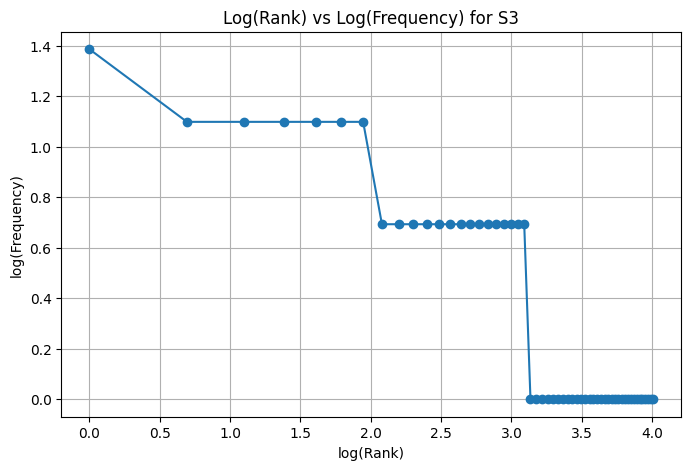


Top 5 bigrams in S1:
[(('.', 'i'), 7), (('.', 'it'), 3), (('when', 'i'), 3), (('i', 'use'), 3), (('use', 'mobile'), 3)]

Top 5 bigrams in S3:
[(('use', 'mobile'), 3), (('mobile', 'hotspot'), 3), (('works', 'another'), 2), (('another', 'computer'), 2), (('tried', 'restarting'), 2)]


In [14]:
# Your code
import string
import math
import matplotlib.pyplot as plt
from collections import Counter
from nltk.util import bigrams
from nltk.stem import PorterStemmer
porter = PorterStemmer()
S1 = [
    token
    for row in df["Ticket_Text"]
    for token in process_ticket(row)["tokens"]
]
S2 = [
    token for token in S1
    if not all(ch in string.punctuation for ch in token)
]
S3 = [
    token
    for row in df["Ticket_Text"]
    for token in process_ticket(row)["final"]
]
S4 = [porter.stem(token.lower()) for token in S3]
def corpus_statistics(name, corpus):
    total = len(corpus)
    unique = len(set(corpus))

    return {
        "Corpus": name,
        "Total Tokens": total,
        "Unique Tokens": unique,
        "TTR": round(unique / total, 4) if total else 0
    }
stats = pd.DataFrame([
    corpus_statistics("S1", S1),
    corpus_statistics("S2", S2),
    corpus_statistics("S3", S3),
    corpus_statistics("S4", S4)
])
print(stats.to_string(index=False))
print("\nTop 10 words in S1:")
print(Counter(S1).most_common(10))
print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))
frequency_list = Counter(S3).most_common()
ranks = list(range(1, len(frequency_list) + 1))
frequencies = [count for word, count in frequency_list]
log_ranks = [math.log(rank) for rank in ranks]
log_frequencies = [math.log(count) for count in frequencies]
plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker="o")
plt.xlabel("log(Rank)")
plt.ylabel("log(Frequency)")
plt.title("Log(Rank) vs Log(Frequency) for S3")
plt.grid(True)
plt.show()
print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))
print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*
From S1 to S3: The ratio goes up because removing repeated punctuation and common words drops the total count much faster than the unique word count.   
From S3 to S4: The ratio goes down because stemming turns different versions of the same word (like "works" and "worked") into one root word, reducing the number of unique words.